# Análisis de Serie de Tiempo: Índice de Precios del Azúcar (2010-2026)


## 1. Paquetes

In [29]:
# Colab (R) ya trae tidyverse; solo instala lo que falte
paquetes <- c("readxl", "dplyr", "ggplot2", "scales", "tidyr")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

suppressPackageStartupMessages({
  library(readxl); library(dplyr); library(ggplot2); library(scales); library(tidyr)
})

Para la lectura y limpieza de los datos, realicé algunos ajustes  sobre el código base para adaptarlo a mi serie. Lo primero que hice fue modificar el parámetro a sheet = 1 ya que mi archivo Excel no traía una hoja llamada "Cuadro", pero mantuve el skip = 2. También renombré la columna principal a indice para que el trabajo sea coherente.

El ajuste más importante está en el cálculo de la variación interanual (var_12m). A diferencia de la serie del codigo... La del azúcar es un índice de precios y no una tasa ya expresada en porcentaje. Por lo tanto, no podíamos llegar y calcular una diferencia simple.

## 2. Lectura y limpieza de datos



In [30]:
archivo <- list.files(c("/content", "."), pattern = "\\.xlsx$", full.names = TRUE)[1]
if (is.na(archivo)) stop("No encontré el .xlsx. Súbelo desde el panel de archivos (ícono de carpeta).")
cat("Leyendo:", archivo, "\n")

raw <- read_excel(archivo, sheet = 1, skip = 2)

df <- raw |>
  select(fecha = 1, indice = 2) |>
  mutate(fecha = as.Date(fecha), indice = as.numeric(indice)) |>
  filter(!is.na(fecha), !is.na(indice)) |>
  arrange(fecha) |>
  mutate(
    anio      = as.integer(format(fecha, "%Y")),
    mes       = as.integer(format(fecha, "%m")),
    media_12m = as.numeric(stats::filter(indice, rep(1/12, 12), sides = 1)),

    var_12m   = (indice / lag(indice, 12) - 1) * 100
  )

cat("Observaciones:", nrow(df), "\n")
summary(df$indice)
tail(df)

Leyendo: ./EI_PROD_BAS_AL (Azucar).xlsx 
Observaciones: 200 


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  63.18   88.87  108.78  109.85  124.72  183.24 

fecha,indice,anio,mes,media_12m,var_12m
<date>,<dbl>,<int>,<int>,<dbl>,<dbl>
2026-03-01,92.84557,2026,3,97.82603,-20.574464
2026-04-01,88.51437,2026,4,95.84323,-21.186040
2026-05-01,95.12157,2026,5,94.65054,-13.078426
2026-06-01,90.00000,2026,6,93.52067,-13.092612
2026-07-01,95.00000,2026,7,92.82489,-8.078703
2026-08-01,106.40000,2026,8,93.05825,2.702929


## 3. Estilo común para los gráficos

para este punto simplemente copie lo que venia en el codigo original y cambie la Fuente de datos..


In [31]:
# Crea un vector con las abreviaturas de los 12 meses en español
meses_es  <- c("Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic")
# Crea una función que convierte una fecha en una etiqueta tipo "Ago 2026"
etq_fecha <- function(x) paste(meses_es[as.integer(format(x, "%m"))], format(x, "%Y"))
# Crea una función que formatea números
num_es    <- function(x) number(x, accuracy = 0.1, decimal.mark = ",")

col_principal <- "#1F4E79"   # azul
col_acento    <- "#E07B39"   # naranjo

# estilo visual común
tema <- theme_minimal(base_size = 13) +
  theme(
    plot.title         = element_text(face = "bold", size = 20, colour = "#1A1A1A"),
    plot.subtitle      = element_text(colour = "#555555", margin = margin(b = 12)),
    plot.caption       = element_text(colour = "#888888", size = 9, hjust = 0),
    plot.title.position = "plot", plot.caption.position = "plot",
    panel.grid.minor   = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = "#E5E5E5"),
    legend.position    = "top", legend.justification = "left",
    plot.background    = element_rect(fill = "white", colour = NA),
    plot.margin        = margin(15, 20, 10, 15)
  )

uente <- "Fuente: Excel de Índice de Precios del Azúcar."

## 4. Evolución del indide de Azucar.
Serie mensual.. Al igual que antes volvi a usar la serie que se recomendaba en el codigo base, solamente cambie lo adapte a mi excel.



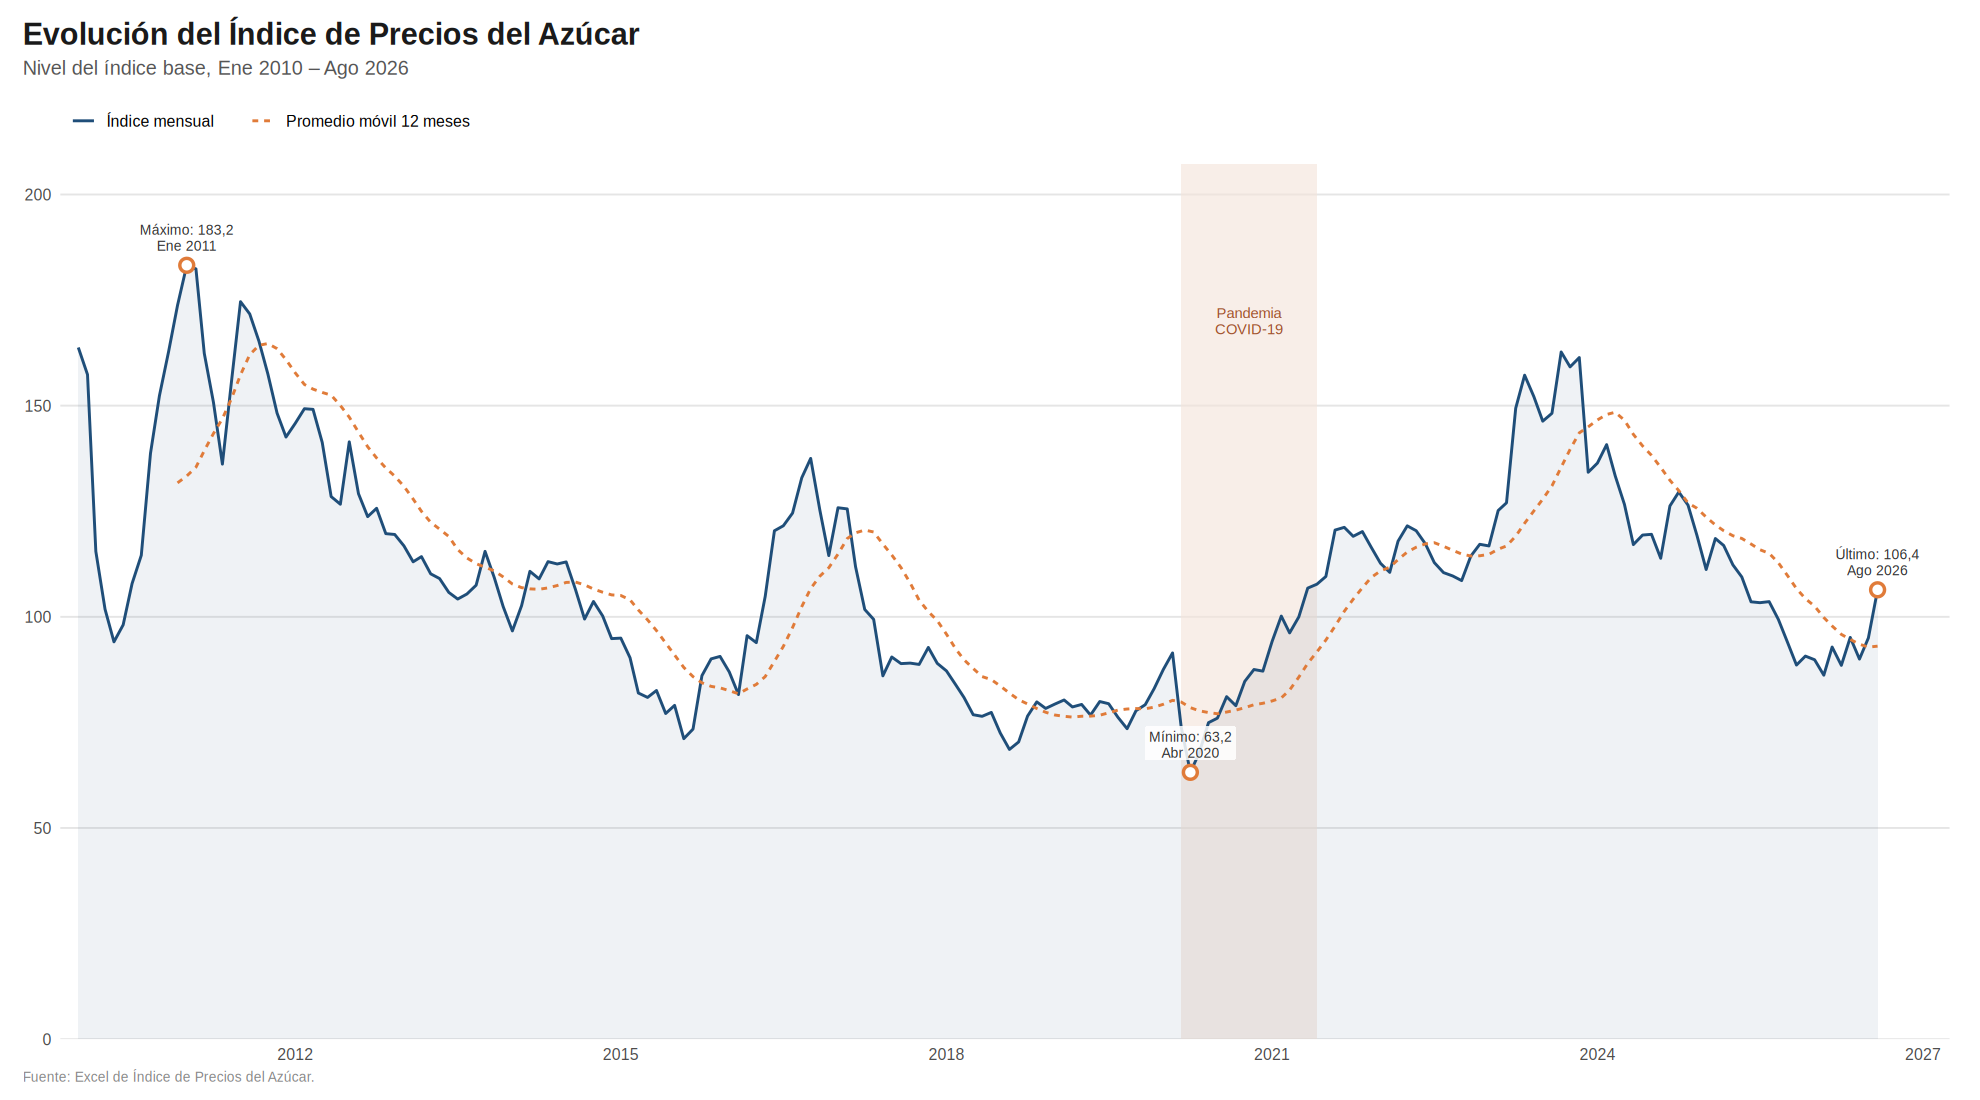

In [32]:
# tamaño y la resolución
options(repr.plot.width = 18, repr.plot.height = 10, repr.plot.res = 110)

# adaptado para indice
hitos <- bind_rows(
  df |> slice_max(indice, n = 1) |> mutate(txt = paste0("Máximo: ", num_es(indice), "\n", etq_fecha(fecha))),
  df |> slice_min(indice, n = 1) |> mutate(txt = paste0("Mínimo: ", num_es(indice), "\n", etq_fecha(fecha))),
  df |> slice_tail(n = 1)      |> mutate(txt = paste0("Último: ", num_es(indice), "\n", etq_fecha(fecha)))
)

g1 <- ggplot(df, aes(fecha)) +
  annotate("rect", xmin = as.Date("2020-03-01"), xmax = as.Date("2021-06-01"),
           ymin = -Inf, ymax = Inf, fill = "#F3E3D8", alpha = .6) +
  annotate("text", x = as.Date("2020-10-15"), y = 170, label = "Pandemia\nCOVID-19",
           size = 3.4, colour = "#A0522D", lineheight = .9) +
  geom_area(aes(y = indice), fill = col_principal, alpha = .07) +
  geom_line(aes(y = indice, colour = "Índice mensual"), linewidth = .9) +
  geom_line(aes(y = media_12m, colour = "Promedio móvil 12 meses"),
            linewidth = .9, linetype = "22", na.rm = TRUE) +
  geom_point(data = hitos, aes(y = indice), size = 3.2, colour = col_acento,
             fill = "white", shape = 21, stroke = 1.6) +
  geom_label(data = hitos, aes(y = indice, label = txt), size = 3.2, vjust = -0.35,
             linewidth = 0, fill = alpha("white", .85), colour = "#333333", lineheight = .95) +
  scale_colour_manual(NULL, values = c("Índice mensual" = col_principal,
                                       "Promedio móvil 12 meses" = col_acento)) +
  scale_x_date(date_breaks = "3 years", date_labels = "%Y",
               expand = expansion(mult = c(.01, .04))) +
  scale_y_continuous(labels = label_number(accuracy = 1),
                     limits = c(0, max(df$indice) + 20), expand = expansion(mult = c(0, .02))) +
  labs(title = "Evolución del Índice de Precios del Azúcar",
       subtitle = paste0("Nivel del índice base, ",
                         etq_fecha(min(df$fecha)), " – ", etq_fecha(max(df$fecha))),
       x = NULL, y = NULL,
       caption = "Fuente: Excel de Índice de Precios del Azúcar.") +
  tema

g1

## 5. Mapa de calor por año y mes
Permite ver de un vistazo los años altos y bajos y el patrón estacional.

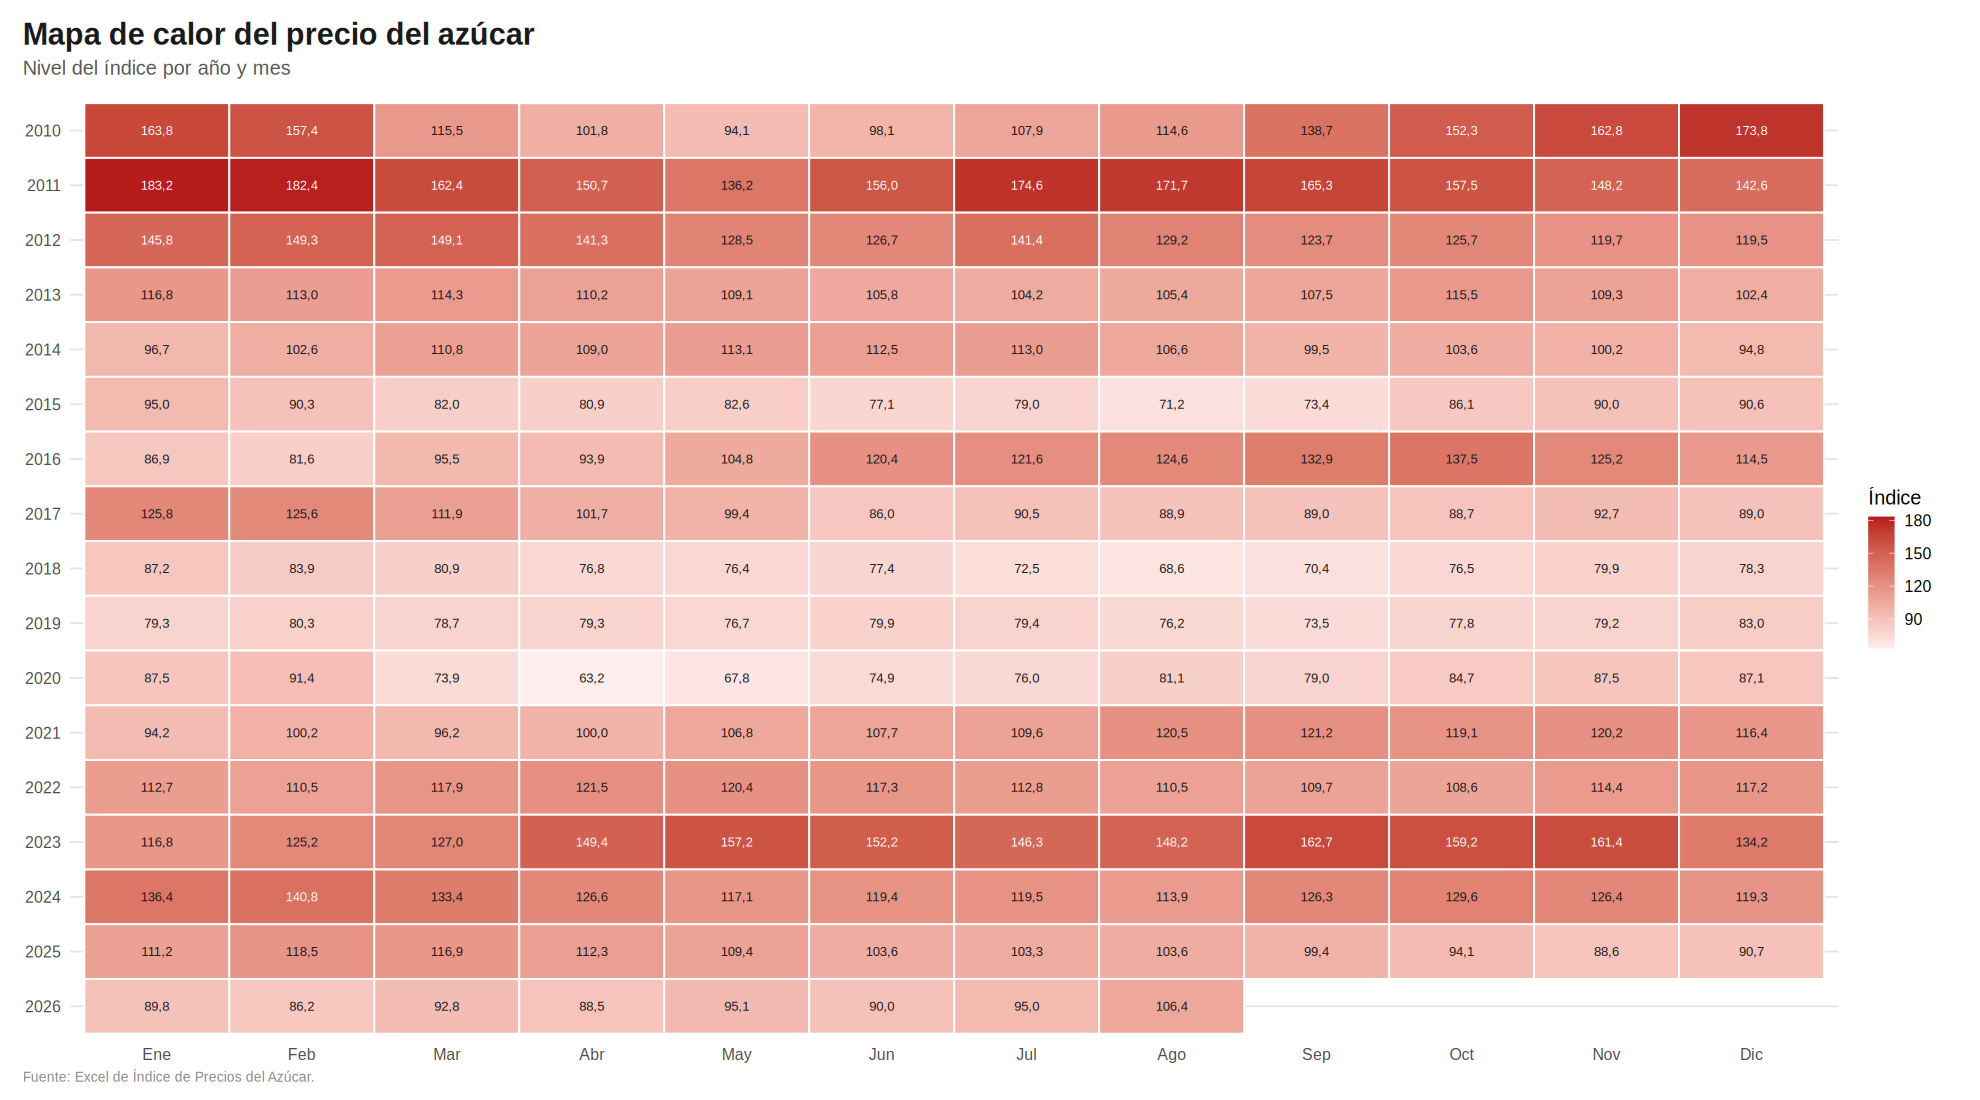

In [33]:
options(repr.plot.width = 18, repr.plot.height = 10)

g2 <- ggplot(df, aes(factor(mes, levels = 1:12, labels = meses_es),
                     factor(anio, levels = rev(sort(unique(anio)))),
                     fill = indice)) +
  geom_tile(colour = "white", linewidth = .6) +
  # Umbral ajustado a > 140 para que los números blancos se lean bien sobre el rojo oscuro
  geom_text(aes(label = num_es(indice), colour = indice > 140), size = 3, show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "#1A1A1A")) +
  scale_fill_gradient(low = "#FDEDEC", high = "#B71C1C", name = "Índice") +
  labs(title = "Mapa de calor del precio del azúcar",
       subtitle = "Nivel del índice por año y mes",
       x = NULL, y = NULL,
       caption = "Fuente: Excel de Índice de Precios del Azúcar.") +
  tema + theme(panel.grid = element_blank(), legend.position = "right")

g2

## 6. Variación en 12 meses
Cuántos puntos porcentuales subió o bajó la tasa respecto del mismo mes del año anterior.

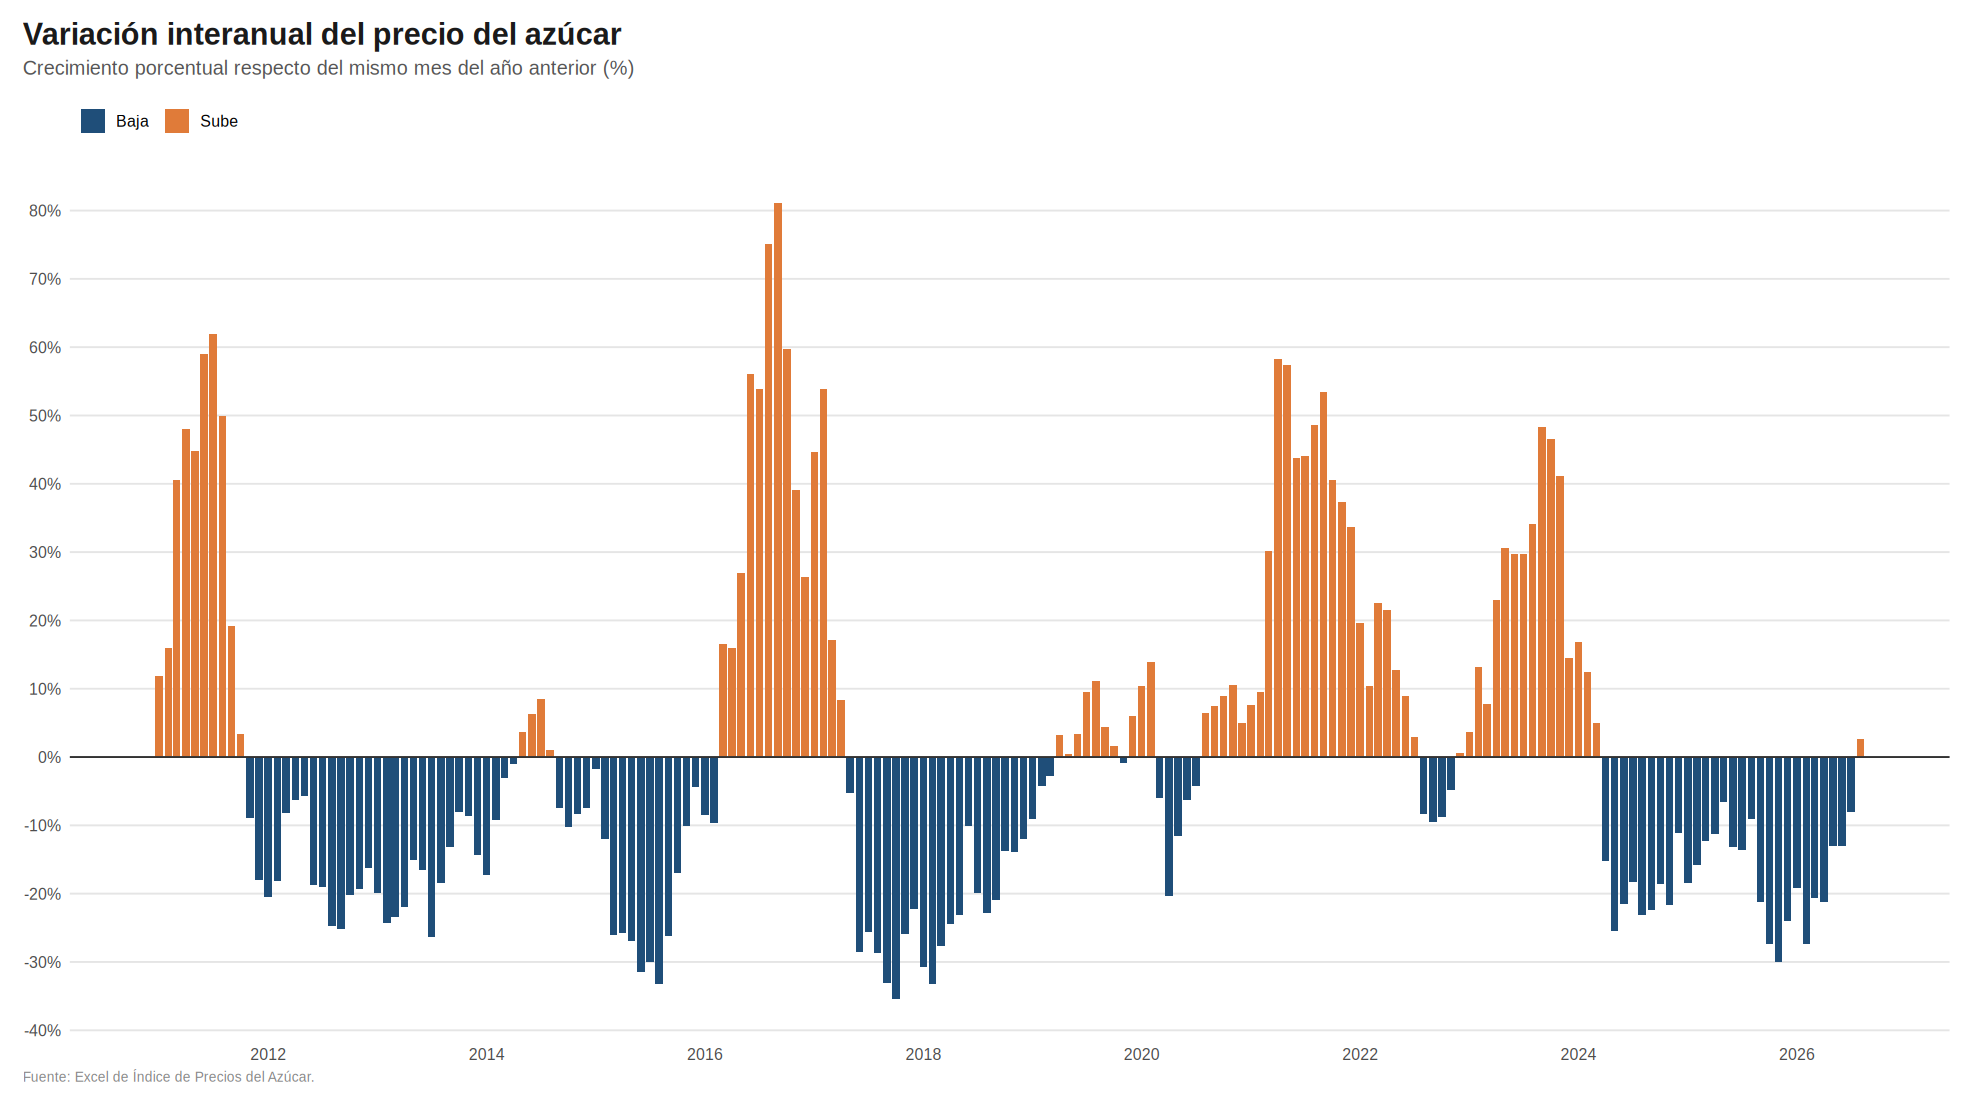

In [34]:
options(repr.plot.width = 18, repr.plot.height = 10)

g3 <- df |>
  filter(!is.na(var_12m)) |>
  ggplot(aes(fecha, var_12m, fill = var_12m > 0)) +
  geom_col(width = 25) +
  geom_hline(yintercept = 0, colour = "#333333") +
  scale_fill_manual(NULL, values = c(`TRUE` = col_acento, `FALSE` = col_principal),
                    labels = c(`TRUE` = "Sube", `FALSE` = "Baja")) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  scale_y_continuous(breaks = breaks_width(10), labels = label_number(accuracy = 1, suffix = "%")) +
  labs(title = "Variación interanual del precio del azúcar",
       subtitle = "Crecimiento porcentual respecto del mismo mes del año anterior (%)",
       x = NULL, y = NULL,
       caption = "Fuente: Excel de Índice de Precios del Azúcar.") +
  tema

g3

# **Interpretación económica y analisis de graficos**
Al evaluar la serie de tiempo del índice de precios del azúcar, resulta evidente que no todas las herramientas visuales poseen la misma utilidad empírica. Si bien el mapa de calor puede resultar enormemente útil en distintos escenarios el hecho de que este mercado sea tan cíclico durante los años provoca que pierda en gran parte su valor. Sin embargo, esta serie nos permite observar un patrón estacional donde los niveles tienden a ser más altos a principios (enero y febrero) y finales de año (octubre y noviembre), cayendo hacia mediados de año (abril a junio) por la época de cosecha.. mas que eso no nos refleja mucho. Por ello, el gráfico de variación interanual a 12 meses resulta mucho más revelador, ya que captura con total claridad la volatilidad del mercado, mostrando variaciones extremas con crecimientos que llegan a superar el 60% interanual y caídas mayores al 30%.

Considero al índice de precios del azúcar como una variable de interés. Al ser un insumo transversal, sus fluctuaciones impactan directamente en la inflación de la canasta de alimentos, afectando el poder adquisitivo de los hogares. Además, desde el ámbito de la economía aplicada, el precio del azúcar resulta ser una variable explicativa fundamental al modelar empíricamente los determinantes globales del sobrepeso en adultos y otras externalidades de salud pública. Para alguien como yo que tiene interés en nutrición, se hace una variable importante.

Revisando los hitos de la serie en el gráfico con promedio móvil, el máximo histórico se alcanzó en enero de 2011 (183,2 puntos). Este peak fue impulsado por el súper ciclo de los commodities y factores climáticos adversos que restringieron la oferta. En contraste, el mínimo se registró en abril de 2020 (63,2 puntos), reflejando un shock negativo de demanda provocado por las cuarentenas de la pandemia de COVID-19, las cuales deprimieron el consumo industrial. Algo esperable.

Finalmente, el valor más reciente de agosto de 2026 se sitúa en 106,4 puntos, ligeramente por debajo del promedio histórico (109,8), con una variación interanual moderada de 2,7%. Esto indica que, tras intensos vaivenes, el precio del commodity está ajustándose hacia el equilibrio, estabilizando sus niveles de crecimiento.